# AI Usage & Impact Analysis: Students vs Professionals

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

## 2. Load Data

In [21]:
df = pd.read_csv('AI_Usage_and_Impact_on_Students_and_Professionals.csv')
print(df.shape)
df.head()

(300, 19)


,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.9,3.0,9.0,11.4,8.4 hrs,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,Chat GPT,Coding,1 hrs,NaN,20,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0,4.7,4.0,7.0,9.2,6.2,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    object 
 1   Age                          277 non-null    object 
 2   Gender                       290 non-null    object 
 3   Country                      290 non-null    object 
 4   User_Type                    300 non-null    object 
 5   Education_Level              287 non-null    object 
 6   Profession                   285 non-null    object 
 7   Monthly_Income               290 non-null    object 
 8   AI_Tool                      289 non-null    object 
 9   AI_Purpose                   287 non-null    object 
 10  AI_Usage_Hours_Per_Day       293 non-null    object 
 11  Tasks_Performed              282 non-null    object 
 12  Monthly_AI_Cost              288 non-null    object 
 13  Productivity_Score  

In [4]:
df.isnull().sum()

User_ID                         0
Age                            23
Gender                         10
Country                        10
User_Type                       0
Education_Level                13
Profession                     15
Monthly_Income                 10
AI_Tool                        11
AI_Purpose                     13
AI_Usage_Hours_Per_Day          7
Tasks_Performed                18
Monthly_AI_Cost                12
Productivity_Score             16
Accuracy_Rating                15
Satisfaction_Score              7
Time_Saved_Hours_Per_Week      10
Work_or_Study_Hours_Per_Day     9
Would_Recommend                 5
dtype: int64

## 3. Data Cleaning

### 3.1 Remove Duplicates

In [5]:
print('Duplicates:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

Duplicates: 12
(288, 19)


### 3.2 Fix Numeric Columns (remove text like 'yrs', '$', 'hrs')

In [6]:
num_cols = ['Age', 'Monthly_Income', 'AI_Usage_Hours_Per_Day', 'Monthly_AI_Cost',
            'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day']

for col in num_cols:
    df[col] = df[col].astype(str).str.replace(r'[^0-9.\-]', '', regex=True)
    df[col] = pd.to_numeric(df[col], errors='coerce')

df[num_cols].describe()

,Age,Monthly_Income,AI_Usage_Hours_Per_Day,Monthly_AI_Cost,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day
count,265.000000,278.000000,281.000000,276.000000,278.000000,279.000000
mean,30.124528,2343.244604,2.941637,9.909420,5.810072,7.253405
std,12.456423,15053.121718,2.463710,13.892148,4.114653,1.995511
min,16.000000,0.000000,0.500000,0.000000,0.000000,2.100000
25%,22.000000,110.750000,1.300000,0.000000,2.725000,6.000000
50%,27.000000,523.500000,2.000000,0.000000,5.000000,7.200000
75%,35.000000,1627.250000,4.000000,20.000000,7.700000,8.400000
max,97.000000,250000.000000,23.000000,100.000000,19.400000,20.000000


### 3.3 Standardise Text Columns

In [7]:
# Gender
df['Gender'] = df['Gender'].str.strip().str.lower().map({
    'male': 'Male', 'm': 'Male', 'female': 'Female', 'f': 'Female',
    'other': 'Other', 'non-binary': 'Non-binary'})

# AI Tool
df['AI_Tool'] = df['AI_Tool'].str.strip().str.lower().map({
    'chatgpt': 'ChatGPT', 'chat gpt': 'ChatGPT',
    'copilot': 'Microsoft Copilot', 'microsoft copilot': 'Microsoft Copilot',
    'gemini': 'Google Gemini', 'google gemini': 'Google Gemini',
    'claude': 'Claude', 'perplexity ai': 'Perplexity AI',
    'grammarly': 'Grammarly', 'meta ai': 'Meta AI', 'deepseek': 'DeepSeek'})

# Country
df['Country'] = df['Country'].str.strip().str.title().replace({
    'U.K.': 'United Kingdom', 'United States Of America': 'United States'})

# Education
df['Education_Level'] = df['Education_Level'].str.strip().str.lower().map({
    "bachelor's": "Bachelor's", 'bachelors': "Bachelor's", 'ba/bsc': "Bachelor's",
    "bachelor's degree": "Bachelor's", 'undergraduate': 'Undergraduate',
    'undergrad': 'Undergraduate', "master's": "Master's", 'masters': "Master's",
    'ma/msc': "Master's", "master's degree": "Master's",
    'high school': 'High School', 'hs': 'High School',
    'diploma': 'Diploma', 'phd': 'PhD', 'ph.d.': 'PhD'})

print(df['Gender'].value_counts(dropna=False))
print(df['AI_Tool'].value_counts(dropna=False))

Gender
Male          145
Female        117
Other          15
NaN            10
Non-binary      1
Name: count, dtype: int64
AI_Tool
ChatGPT              119
Google Gemini         39
Microsoft Copilot     33
Claude                31
Perplexity AI         23
Grammarly             14
Meta AI               10
NaN                   10
DeepSeek               9
Name: count, dtype: int64


### 3.4 Remove Impossible Values

In [8]:
df.loc[(df['Age'] < 10) | (df['Age'] > 80), 'Age'] = np.nan
df.loc[df['AI_Usage_Hours_Per_Day'] > 24, 'AI_Usage_Hours_Per_Day'] = np.nan
df.loc[df['Work_or_Study_Hours_Per_Day'] > 24, 'Work_or_Study_Hours_Per_Day'] = np.nan
df.loc[df['Monthly_Income'] < 0, 'Monthly_Income'] = np.nan
df.loc[df['Time_Saved_Hours_Per_Week'] < 0, 'Time_Saved_Hours_Per_Week'] = np.nan

### 3.5 Handle Missing Values

In [9]:
# Numeric columns -> median (by User_Type)
all_num = num_cols + ['Productivity_Score', 'Accuracy_Rating', 'Satisfaction_Score']
for col in all_num:
    df[col] = df[col].fillna(df.groupby('User_Type')[col].transform('median'))
    df[col] = df[col].fillna(df[col].median())

# Text columns -> 'Unknown'
text_cols = ['Gender', 'Country', 'Education_Level', 'Profession',
             'AI_Tool', 'AI_Purpose', 'Tasks_Performed', 'Would_Recommend']
for col in text_cols:
    df[col] = df[col].fillna('Unknown')

print('Remaining nulls:', df.isnull().sum().sum())
print(df.shape)

Remaining nulls: 0
(288, 19)


In [10]:
df.to_csv('ai_usage_cleaned.csv', index=False)

## 4. Exploratory Data Analysis

### 4.1 Most Used AI Tools

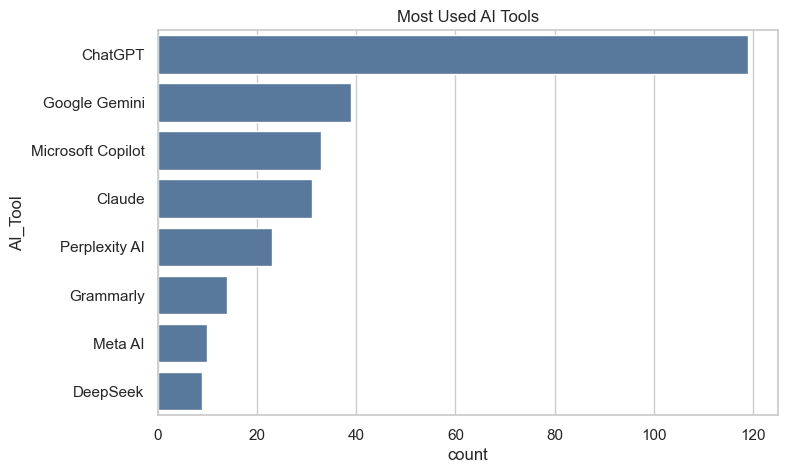

In [11]:
known = df[df['AI_Tool'] != 'Unknown']

plt.figure(figsize=(8, 5))
sns.countplot(data=known, y='AI_Tool', order=known['AI_Tool'].value_counts().index, color='#4C78A8')
plt.title('Most Used AI Tools')
plt.show()

### 4.2 AI Purpose: Students vs Professionals

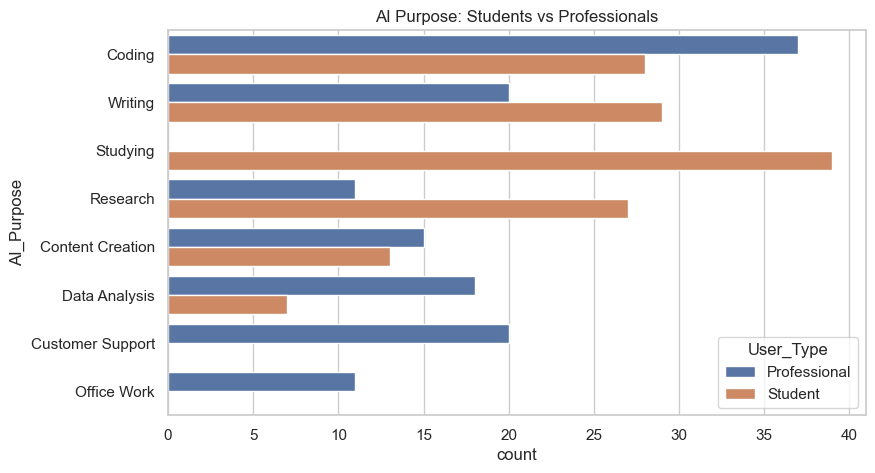

In [12]:
k = df[df['AI_Purpose'] != 'Unknown']

plt.figure(figsize=(9, 5))
sns.countplot(data=k, y='AI_Purpose', hue='User_Type', order=k['AI_Purpose'].value_counts().index)
plt.title('AI Purpose: Students vs Professionals')
plt.show()

### 4.3 Free vs Paid Users

      Productivity_Score  Satisfaction_Score  Time_Saved_Hours_Per_Week
Plan                                                                   
Free                5.37                6.25                       5.73
Paid                5.04                5.98                       5.85


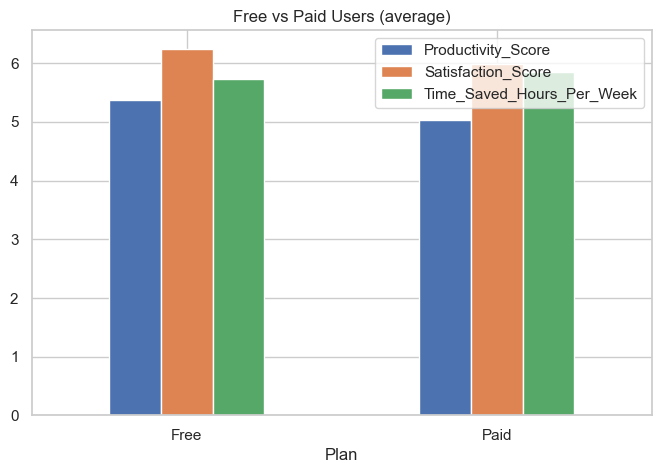

In [13]:
df['Plan'] = np.where(df['Monthly_AI_Cost'] == 0, 'Free', 'Paid')

plan = df.groupby('Plan')[['Productivity_Score', 'Satisfaction_Score', 'Time_Saved_Hours_Per_Week']].mean().round(2)
print(plan)

plan.plot(kind='bar', figsize=(8, 5))
plt.title('Free vs Paid Users (average)')
plt.xticks(rotation=0)
plt.show()

### 4.4 Daily AI Usage vs Weekly Time Saved

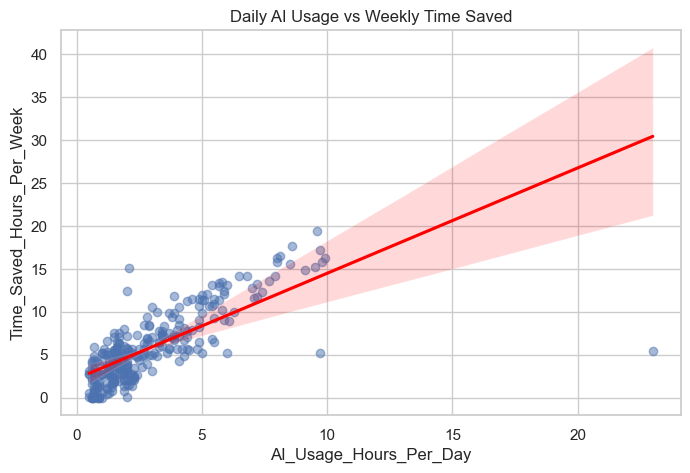

In [14]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='AI_Usage_Hours_Per_Day', y='Time_Saved_Hours_Per_Week', scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
plt.title('Daily AI Usage vs Weekly Time Saved')
plt.show()

### 4.5 Productivity: Students vs Professionals

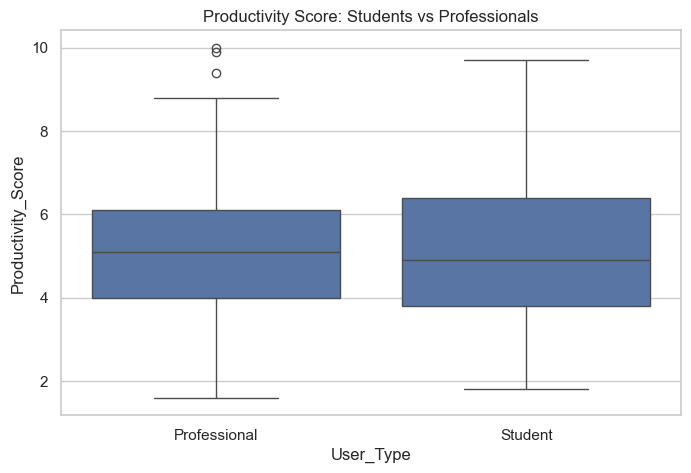

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='User_Type', y='Productivity_Score')
plt.title('Productivity Score: Students vs Professionals')
plt.show()

### 4.6 Average Satisfaction by AI Tool

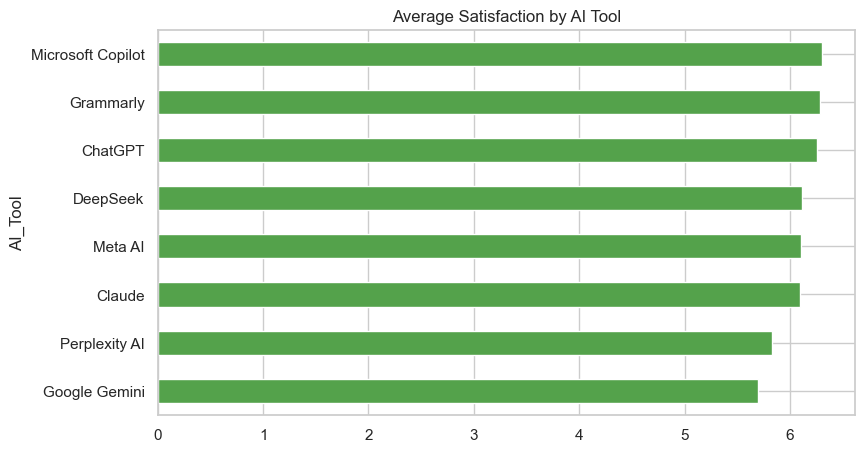

In [16]:
sat = known.groupby('AI_Tool')['Satisfaction_Score'].mean().sort_values()

plt.figure(figsize=(9, 5))
sat.plot(kind='barh', color='#54A24B')
plt.title('Average Satisfaction by AI Tool')
plt.show()

### 4.7 Would Recommend?

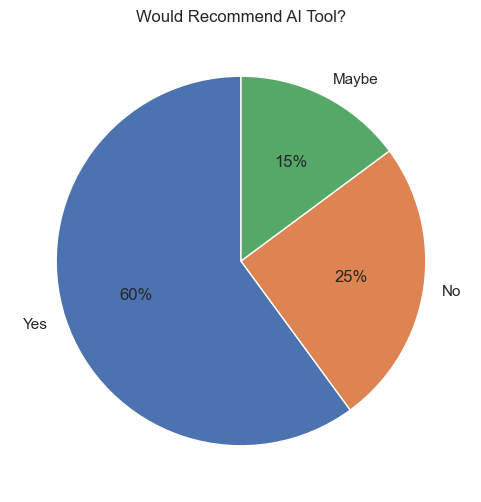

In [17]:
rec = df[df['Would_Recommend'] != 'Unknown']['Would_Recommend'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(rec, labels=rec.index, autopct='%1.0f%%', startangle=90)
plt.title('Would Recommend AI Tool?')
plt.show()

### 4.8 Monthly Income Distribution (log scale)

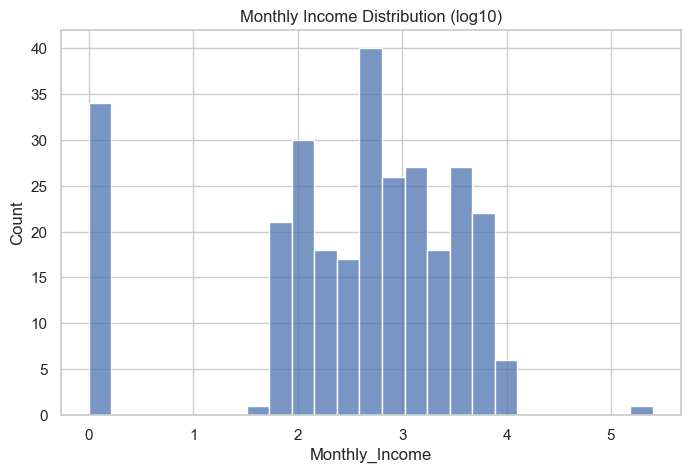

In [18]:
plt.figure(figsize=(8, 5))
sns.histplot(np.log10(df['Monthly_Income'] + 1), bins=25)
plt.title('Monthly Income Distribution (log10)')
plt.show()

### 4.9 Correlation Heatmap

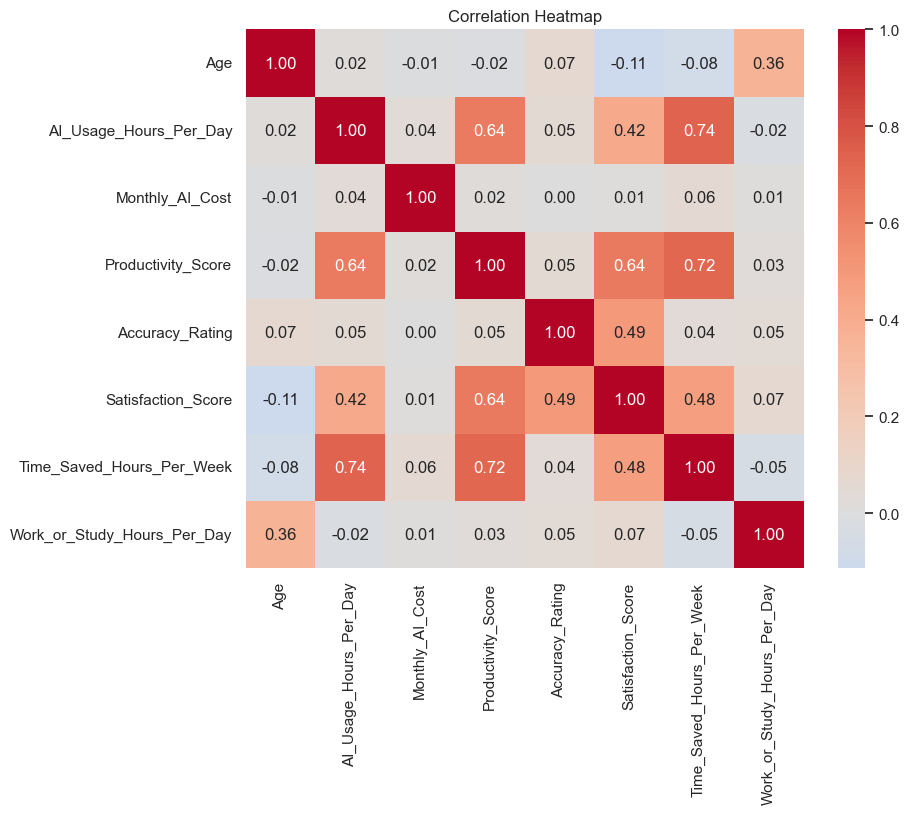

In [19]:
cols = ['Age', 'AI_Usage_Hours_Per_Day', 'Monthly_AI_Cost', 'Productivity_Score',
        'Accuracy_Rating', 'Satisfaction_Score', 'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day']

plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

## 5. Key Insights
- ChatGPT is the most used AI tool, and Coding is the top use-case.
- Around 55% of users use a free plan.
- Paid users do not show higher productivity than free users.
- Productivity is strongly linked with Time Saved, Satisfaction and Usage Hours.
- Age, Cost and Accuracy have almost no effect on productivity.
- Note: this is correlation, not causation (small survey of 288 records).